# E-commerce Funnel & Retention Analysis — Google Merchandise Store (GA4 sample)

**Dataset:** `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*` — real
(obfuscated) GA4 event export from the Google Merchandise Store, Nov 2020–Jan 2021.
92 daily tables, 4,295,584 events, 270,154 users, 360,129 sessions, 4,452 purchases.
Full profiling in `docs/data-profile.md`.

**Approach:** every number below comes from a SQL file in `sql/` run against
BigQuery (see `src/run_queries.py`) and saved to `data/*.csv`. This notebook reads
those CSVs and the PNGs in `charts/` — it does not re-query BigQuery, so re-running
it costs nothing and never drifts from what's on disk. Each section is
**question → query → chart → so what** for a PM audience.


In [1]:
import pandas as pd
from pathlib import Path
from IPython.display import Image, display, Markdown

ROOT = Path.cwd()
DATA = ROOT / "data"
CHARTS = ROOT / "charts"
SQL = ROOT / "sql"

pd.set_option("display.max_rows", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

def show_sql(name):
    display(Markdown(f"```sql\n{(SQL / name).read_text(encoding='utf-8')}\n```"))


## 1. What does daily traffic, conversion, and revenue look like?

**Question:** Is traffic and conversion stable day to day, and how much revenue
does the store make? **Query:** `sql/01_kpis_daily.sql`.


In [2]:
df01 = pd.read_csv(DATA / "01_kpis_daily.csv")
df01.describe()[["users", "sessions", "conversion_rate_pct", "revenue_usd", "avg_order_value_usd"]]


,users,sessions,conversion_rate_pct,revenue_usd,avg_order_value_usd
count,92.00,92.00,92.00,92.00,91.00
mean,"3,468.11","3,923.63",1.28,"3,359.50",58.51
std,873.11,"1,019.44",0.58,"3,067.96",21.04
min,"1,919.00","2,170.00",0.47,0.00,0.00
25%,"2,851.00","3,250.25",0.76,"1,095.75",52.47
50%,"3,403.50","3,847.00",1.21,"2,373.00",63.54
75%,"3,995.25","4,581.00",1.67,"5,211.25",71.85
max,"6,689.00","7,588.00",2.77,"11,956.00",107.38


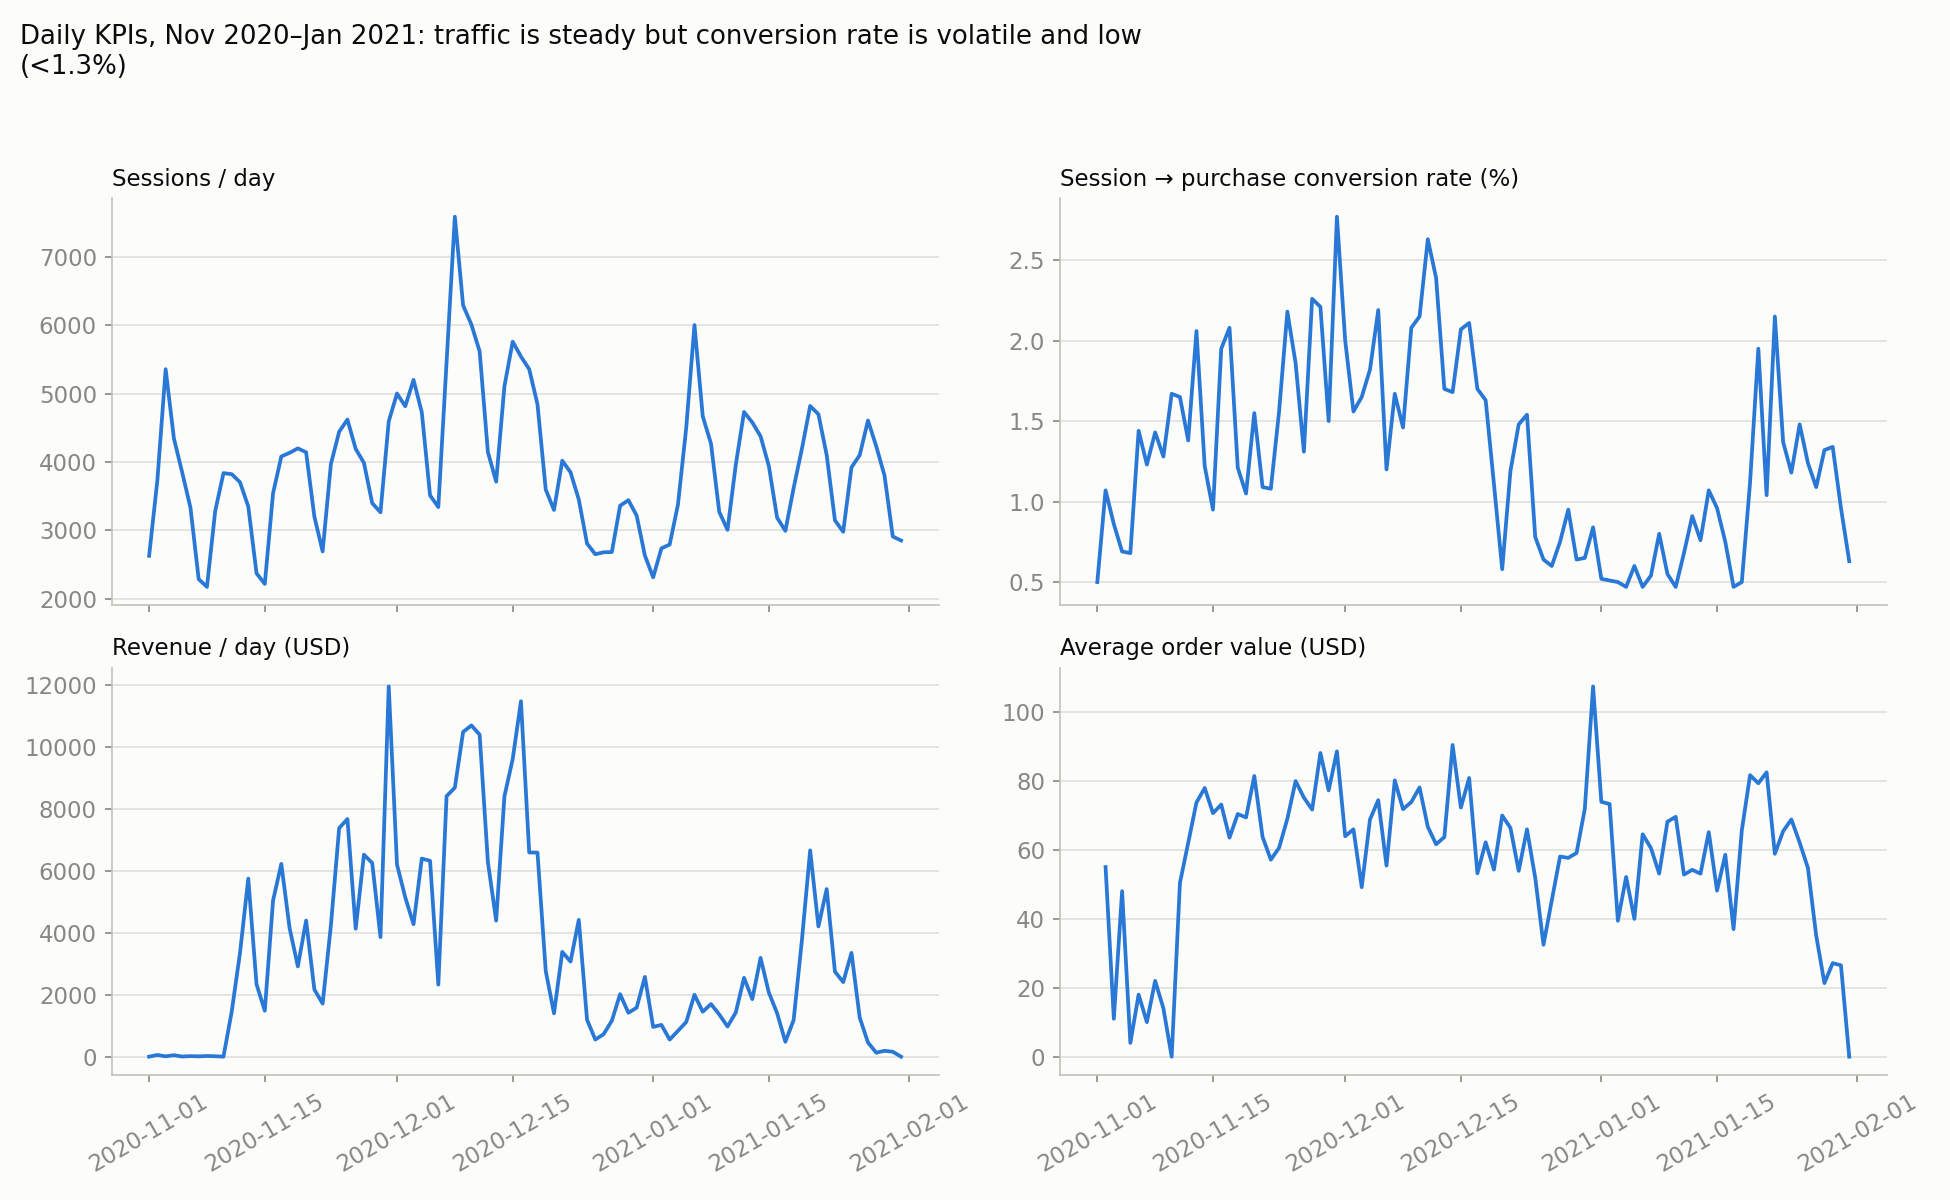

In [3]:
display(Image(filename=str(CHARTS / "daily_kpis.png")))

**So what:** Sessions/day hold a fairly steady ~2,500–6,000 band (one spike to
~7,500 on 2020-12-05, likely a promo day), but the **conversion rate swings between
0.5% and 2.8%** day to day with no steady upward trend across the 3-month window.
A PM reading this should not assume "more traffic" is the lever — conversion rate
is the far more volatile, and arguably more controllable, variable here.


## 2. Where exactly do users drop out of the purchase funnel?

**Question:** Of all sessions, what % make it through each step to purchase, and
where is the single biggest drop? **Query:** `sql/02_funnel.sql`. Session-level:
a step only counts if every earlier step happened in the *same* session
(`user_pseudo_id` + `ga_session_id`).


In [4]:
df02 = pd.read_csv(DATA / "02_funnel.csv")
df02


,step_order,step_name,sessions,pct_of_initial,step_conversion_pct,dropoff_pct
0,1,session_start,354857,100.00,NaN,NaN
1,2,view_item,75271,21.21,21.21,78.79
2,3,add_to_cart,14897,4.20,19.79,80.21
3,4,begin_checkout,5868,1.65,39.39,60.61
4,5,add_shipping_info,5868,1.65,100.00,0.00
5,6,add_payment_info,3810,1.07,64.93,35.07
6,7,purchase,2816,0.79,73.91,26.09


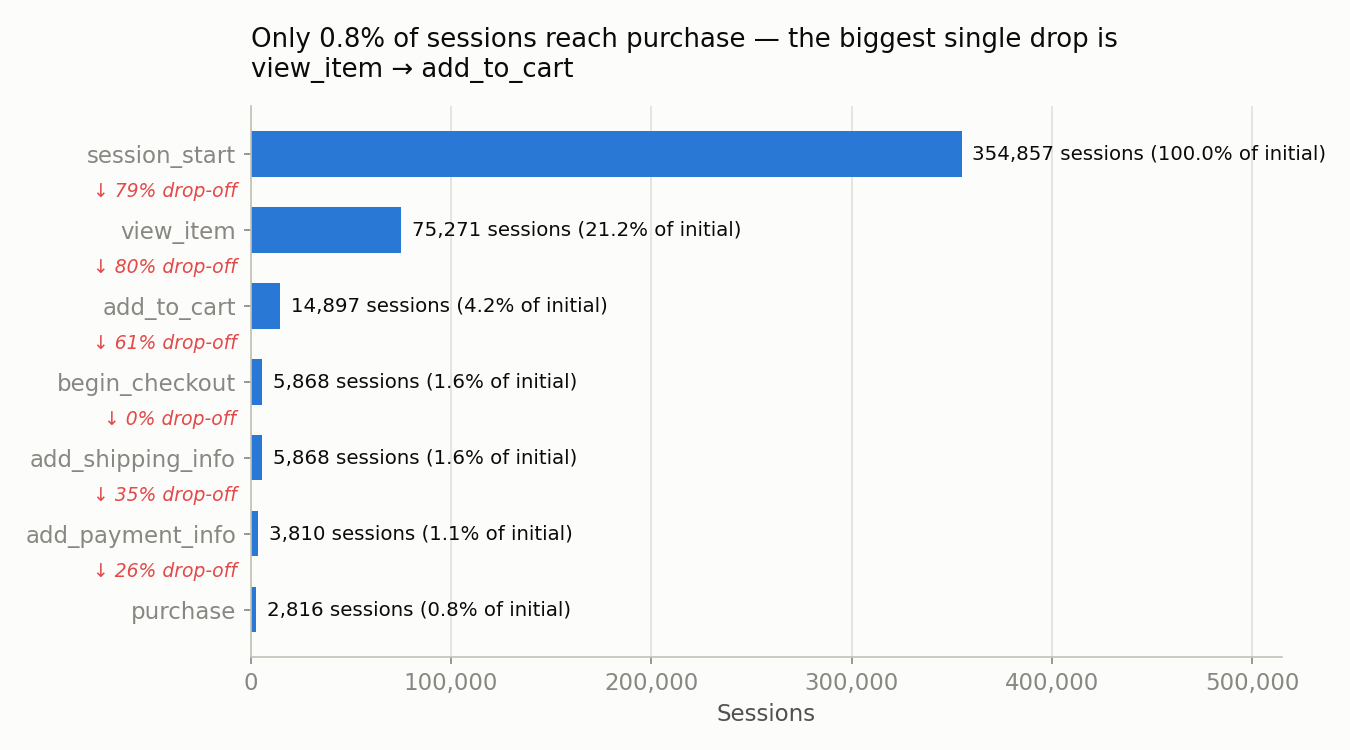

In [5]:
display(Image(filename=str(CHARTS / "funnel.png")))

**So what:** Only **0.79% of sessions** (2,816 of 354,857) reach purchase. The
two biggest drops are **session_start → view_item (78.8% drop-off)** and
**view_item → add_to_cart (80.2% drop-off)** — by rate, add_to_cart is the single
leakiest step; by absolute session count lost, session_start → view_item loses more
(279,586 vs. 60,374 sessions). Notably, **begin_checkout → add_shipping_info has a
literal 0% drop-off** (5,868 → 5,868) in every segment we checked — that step looks
auto-populated rather than a real user decision point, which matters for anyone
designing a checkout experiment (see `docs/experiments.md`).


## 3. Does the funnel shape change by device, traffic source, or country?

**Question:** Is the drop-off universal, or concentrated in a specific segment?
**Query:** `sql/03_funnel_segments.sql`, same funnel broken out by device category,
traffic medium/source, and top-10 countries by volume (segments under 100 sessions
flagged `low_sample` and excluded from decisions).


In [6]:
df03 = pd.read_csv(DATA / "03_funnel_segments.csv")
df03[df03.step_order == 7].sort_values("sessions", ascending=False)[
    ["segment_type", "segment_value", "sessions", "pct_of_initial", "low_sample"]
].head(15)


,segment_type,segment_value,sessions,pct_of_initial,low_sample
76,device_category,desktop,1592,0.77,False
6,country,United States,1254,0.80,False
83,device_category,mobile,1162,0.82,False
139,traffic_source,google,819,0.64,False
97,traffic_medium,organic,788,0.65,False
153,traffic_source,(direct),639,0.78,False
104,traffic_medium,(none),639,0.78,False
146,traffic_source,<Other>,632,0.66,False
111,traffic_medium,referral,608,0.98,False
125,traffic_medium,(data deleted),390,1.82,False


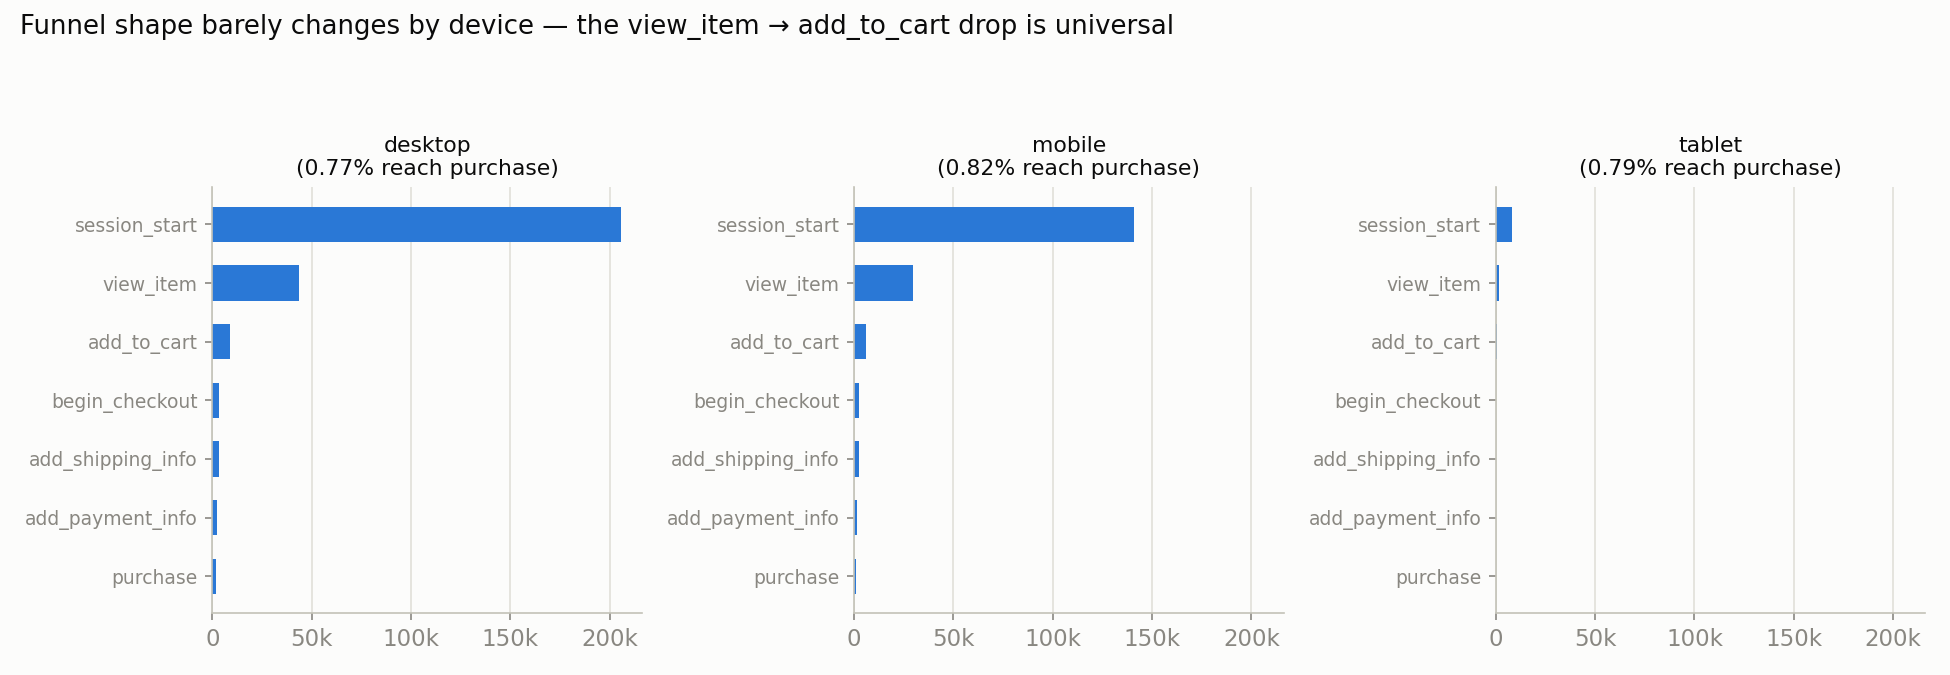

In [7]:
display(Image(filename=str(CHARTS / "funnel_by_segment.png")))

**So what:** The funnel shape is remarkably **consistent across devices**
(0.77% desktop, 0.82% mobile, 0.79% tablet reach purchase) — device is not the
story. The more interesting spread is in traffic source: **`(data deleted)`
traffic converts highest end-to-end (1.82% of its sessions purchase)** while
**`cpc` (paid search) converts lowest among channels with real volume (0.59%)**,
a signal worth validating before spending more on paid acquisition.


## 4. Do users come back after their first visit?

**Question:** What fraction of each weekly cohort returns in weeks 1–8 after first
visit? **Query:** `sql/04_cohort_retention.sql`.


In [8]:
df04 = pd.read_csv(DATA / "04_cohort_retention.csv")
df04[df04.week_number == 1].sort_values("cohort_week")


,cohort_week,cohort_size,week_number,active_users,retention_pct
1,2020-10-26,2365,1,256,10.82
10,2020-11-02,19374,1,1227,6.33
19,2020-11-09,16232,1,1092,6.73
28,2020-11-16,18167,1,1052,5.79
37,2020-11-23,20072,1,1023,5.10
46,2020-11-30,22034,1,1192,5.41
55,2020-12-07,28545,1,954,3.34
63,2020-12-14,24839,1,716,2.88
70,2020-12-21,17430,1,447,2.56
76,2020-12-28,16615,1,411,2.47


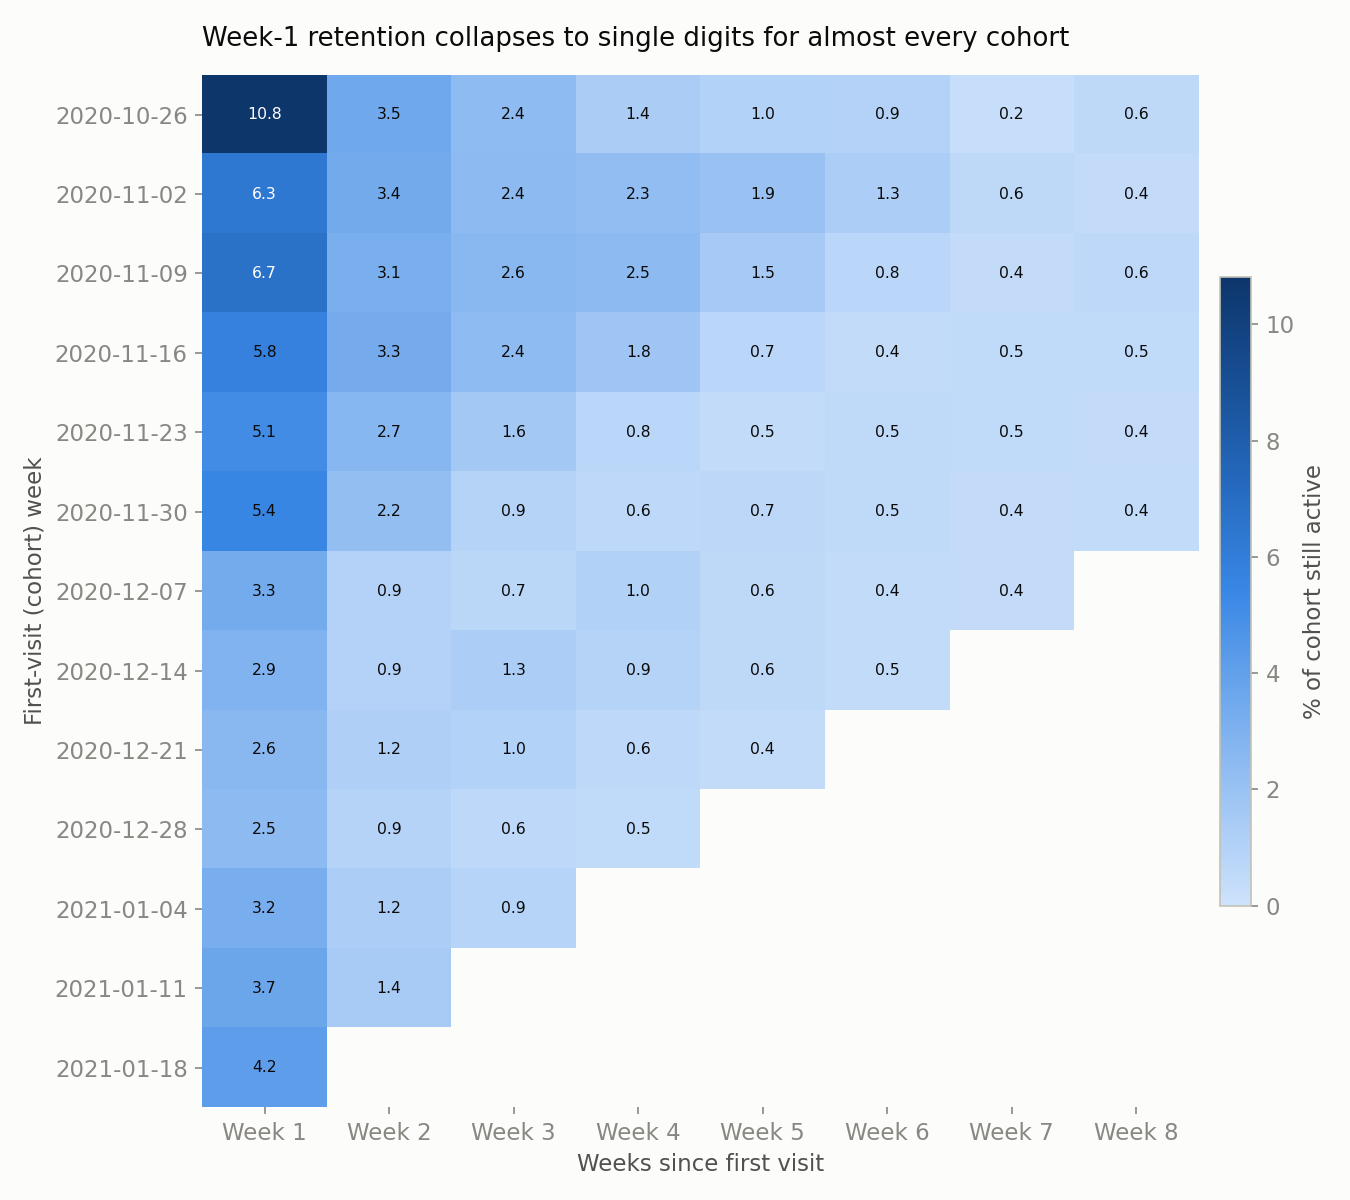

In [9]:
display(Image(filename=str(CHARTS / "cohort_retention_heatmap.png")))

**So what:** Week-1 retention is **6–11% for every cohort** and decays to
under 1% by week 4 in almost every case. This is a store with essentially no
built-in return-visit loop — nearly all revenue comes from first-visit conversion,
not repeat purchasing, which should directly inform whether the team invests in
acquisition (bigger top of funnel) vs. retention (lifecycle email, loyalty) — on
this data, acquisition and first-visit conversion dominate.


## 5. Which product categories underperform?

**Question:** Which categories get viewed a lot but rarely added to cart?
**Query:** `sql/05_product_funnel.sql`.

**Data-quality note (see `docs/data-profile.md`):** `item_id`/`item_category` on
`purchase` events use a near-disjoint taxonomy from `view_item`/`add_to_cart`
events in this obfuscated sample (only 5 of 427 viewed items, and 15 of 75
categories, ever appear on a purchase line item). So this query reports
view-to-cart rate (consistent taxonomy) and top purchased categories by revenue
(purchase's own taxonomy) **separately** rather than chaining a fabricated
view→cart→purchase-by-item rate.


In [10]:
df05 = pd.read_csv(DATA / "05_product_funnel.csv")
df05[df05.query_type == "category_view_to_cart"].sort_values("pct_1").head(10)


,query_type,segment_label,metric_1,metric_2,metric_3,pct_1
61,category_view_to_cart,YouTube,37,0,NaN,0.00
62,category_view_to_cart,Electronics/,30,0,NaN,0.00
58,category_view_to_cart,Kids-Youth/,61,0,NaN,0.00
54,category_view_to_cart,Fun/,164,0,NaN,0.00
59,category_view_to_cart,Accessories,57,0,NaN,0.00
66,category_view_to_cart,Women's Warm Gear/,12,0,NaN,0.00
65,category_view_to_cart,Kid's-Toddler/,14,0,NaN,0.00
74,category_view_to_cart,Men's Warm Gear,1,0,NaN,0.00
72,category_view_to_cart,Miscellaneous/,6,0,NaN,0.00
73,category_view_to_cart,Fun,4,0,NaN,0.00


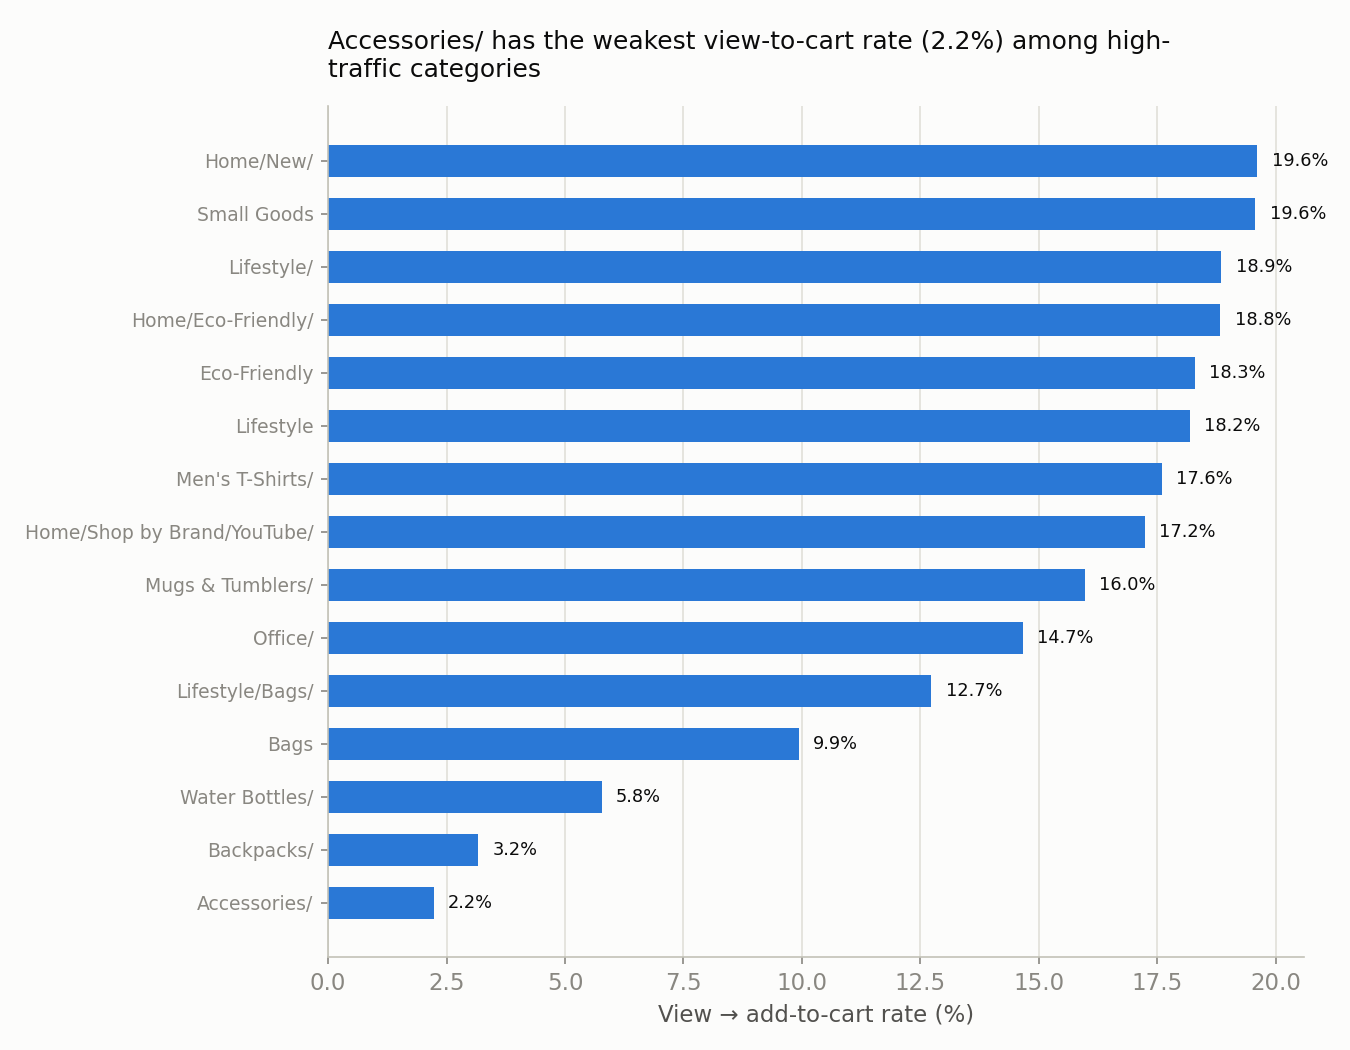

In [11]:
display(Image(filename=str(CHARTS / "product_view_to_cart.png")))

**So what:** **Accessories/ (2.2%), Backpacks/ (3.2%), and Water Bottles/
(5.8%)** have the weakest view-to-cart rates among high-traffic categories — all
well under the ~20–25% that most apparel categories achieve. That's a merchandising
or pricing-page problem specific to those categories, not a site-wide issue.


## 6. Are there time-of-day or day-of-week conversion patterns?

**Question:** Should marketing/ops concentrate effort on specific hours or days?
**Query:** `sql/06_time_patterns.sql` (bucketed by each session's first-event
timestamp, UTC — see data-profile for why local time isn't available).


In [12]:
df06 = pd.read_csv(DATA / "06_time_patterns.csv")
df06.sort_values("conversion_rate_pct", ascending=False).head(10)


,day_of_week,day_of_week_num,hour_of_day_utc,sessions,converting_sessions,conversion_rate_pct
144,Saturday,7,0,1993,42,2.11
142,Friday,6,22,1956,41,2.10
45,Monday,2,21,2350,49,2.09
147,Saturday,7,3,1891,38,2.01
135,Friday,6,15,2144,42,1.96
125,Friday,6,5,2253,44,1.95
61,Tuesday,3,13,2604,50,1.92
77,Wednesday,4,5,2496,48,1.92
89,Wednesday,4,17,2512,47,1.87
46,Monday,2,22,2323,42,1.81


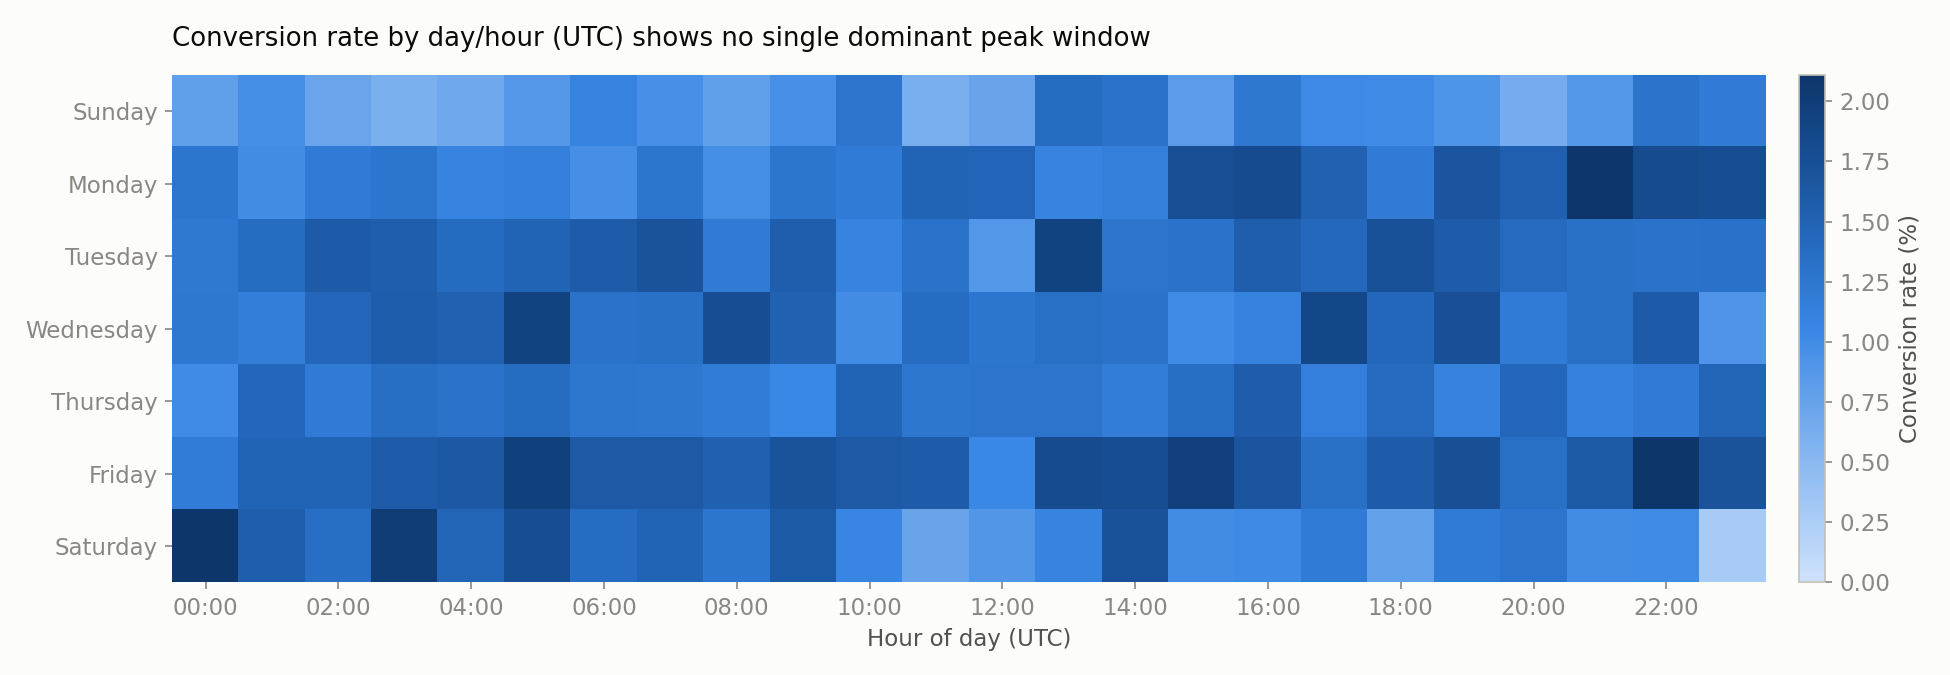

In [13]:
display(Image(filename=str(CHARTS / "time_patterns_heatmap.png")))

**So what:** There is **no clean, dominant peak window** — conversion rate is
noisy hour-to-hour (each cell is ~1,500–1,700 sessions, so swings of a few purchases
move the rate visibly). We would not recommend dayparting spend or launching a
time-boxed promo off this signal alone without a larger sample.


## Where this leads

Full write-up with exact numbers: `docs/insights.md`. Three A/B test designs
(with baseline rates from this data and `statsmodels`-computed sample sizes) for
the leakiest step: `docs/experiments.md`. One-page recommendation memo:
`docs/recommendation-memo.md`. Metric tree: `docs/metric-tree.md`.
